<a href="https://colab.research.google.com/github/promdeejai/flashcard-legal/blob/main/project_323_69_02_v4_king_county.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# กลุ่มที่ 02 : วอดส์

## โครงงาน 229323 Data Manipulation: ตลาดบ้าน King County ปี 2014-15 เทียบกับปี 2021-22

### สมาชิกในกลุ่ม (Section 2)

| ลำดับ | รหัสนักศึกษา | ชื่อ - นามสกุล | หน้าที่ในกลุ่ม |
|:---:|:---:|---|---|
| 1 | 670110394 | สุพิชชา รุจิรวรรณคีรี | Part 1 บทนำ เป้าหมาย และการเลือก dataset |
| 2 | 671510303 | สุวิจักขณ์ อินต๊ะพิงค์ | Part 2.1-2.2 สำรวจ กรอง และทำความสะอาดข้อมูล |
| 3 | 671510287 | สิรวิชญ์ สมเพาะ | Part 2.3 สร้างคอลัมน์ใหม่ สรุปกลุ่ม และรวมตารางข้อมูล |
| 4 | 670110374 | ณฐนน ชัยชนะบุตร | Part 3.1-3.3 Insight และ Visualization |
| 5 | 680510780 | ธนัชพร หอมจันทร์ | Part 3.4-3.5 Insight รายย่าน ทดสอบสมมติฐาน และ Part 4 สรุปผล |

### Dataset ที่ใช้

| ชื่อในโค้ด | Dataset | ลิงก์ |
|---|---|---|
| DF1 | USA Real Estate Dataset (Realtor.com) ใช้เฉพาะบ้านใน King County | https://www.kaggle.com/datasets/ahmedshahriarsakib/usa-real-estate-dataset |
| DF2  | House Sales in King County, USA | https://www.kaggle.com/datasets/harlfoxem/housesalesprediction |

# Part 1: บทนำและเป้าหมาย

ราคาบ้านใน King County ในช่วงปีให้หลัง มีแนวโน้มที่เติบโตขึ้นสาเหตุหลักมาจากเศรษฐกิจ หรือวิถีชีวิตของผู้คน และอีกสาเหตุที่ขาดไม่ได้คือหลังช่วงเกิดโรคระบาดอย่างโควิด โดย King County เป็นศูนย์กลางทางเศรษฐกิจที่สำคัญที่สุดแห่งหนึ่งในอเมริกา และเกิดเกิดลงทุนมากมาย จึงเป็นไปได้ว่ามูลค่าด้านอสังการิมทรัพย์ที่นี่อาจสร้างเป็นกำไร และสามารถเป็นตัวเลือกของใครหลายคนในการย้ายที่อยู่อาศัยในอนาคต

แยกการวิเคราะห์เป็น 2 ชุดข้อมูล:
- ข้อมูลที่ 1 คือ ข้อมูลประกาศขายบ้านทั่วสหรัฐฯ จาก Realtor.com ใช้เฉพาะบ้านใน King County ที่ขายแล้วช่วงปลายปี 2021 ถึงกลางปี 2022 เป็นตัวแทนปี 2021-2022
- ข้อมูลที่ 2 คือ ข้อมูลการขายบ้านใน King County ช่วงกลางปี 2014 ถึงกลางปี 2015 เป็นตัวแทนปี 2014-15


> **เป้าหมายของโครงงานนี้**
>
> เทียบตลาดบ้าน King County ปี 2014-15 กับปี 2021-22 ว่าราคาบ้านเปลี่ยนไปเท่าไร เมื่อเทียบบ้านประเภทเดียวกัน และหาย่านที่ราคาโตเร็วที่สุด เพื่อใช้ประกอบการตัดสินใจซื้อบ้านหรือลงทุน


|  | ข้อมูล |
|---|---|
| Q1 | ราคาบ้านใน King County ขึ้นไปเท่าไรจากปี 2014-15 ถึง 2021-22 |
| Q2 | ข้อมูลสองชุดเก็บบ้านต่างกันอย่างไร และต้องปรับอย่างไรก่อนเทียบ |
| Q3 | ขนาดบ้านและจำนวนห้องสัมพันธ์กับราคาเหมือนเดิมไหม |
| Q4 | ย่านใดราคาโตเร็วที่สุด และย่านที่โตเร็วมีลักษณะอย่างไร |

# Part 2: การจัดดำเนินการข้อมูล (Data Manipulation)

แบ่งเป็น 3 ขั้นตอน
1. การสำรวจและทำความเข้าใจข้อมูล ดูโครงสร้าง สถิติเบื้องต้น และค่าที่หายไป
2. การกรอง จัดเรียง และจัดกลุ่มข้อมูล เลือกเฉพาะบ้านใน King County กรองแถวที่ผิด และแก้ค่าที่ผิด
3. การคำนวณและผสานตารางข้อมูล สร้างคอลัมน์ใหม่ สรุปค่าตามกลุ่ม และรวมตารางด้วย key column

## 2.0 นำเข้าไลบรารีและโหลดข้อมูล

In [ ]:
import pandas as pd #ใช้จัดการตารางข้อมูล (DataFrame)
import numpy as np #ใช้คำนวณตัวเลข
import matplotlib.pyplot as plt #ใช้สร้างกราฟ
import seaborn as sns #ใช้สร้างกราฟให้สวยและง่ายขึ้น
from scipy import stats #ใช้ทดสอบสมมติฐานทางสถิติ

pd.set_option('display.max_columns', 50) #แสดงคอลัมน์ได้สูงสุด 50 คอลัมน์ (DF2 มี 21 คอลัมน์ ถ้าไม่ตั้งจะถูกย่อเป็น ...)
pd.set_option('display.float_format', '{:,.2f}'.format) #แสดงตัวเลขทศนิยม 2 ตำแหน่ง มีคอมม่า อ่านง่ายขึ้น

โหลดข้อมูลจากลิงก์ Kaggle ด้วย `kagglehub` เพื่อให้ทุกคนในกลุ่มรันได้โดยไม่ต้องส่งไฟล์ข้อมูลให้กัน และระบุเวอร์ชันของ dataset ไว้ให้ทุกคนได้ข้อมูลชุดเดียวกัน (ถ้าเครื่องไหนยังไม่มี `kagglehub` ให้รัน `!pip install kagglehub` ก่อน)

In [ ]:
import kagglehub #ใช้ดาวน์โหลด dataset จาก Kaggle

#ดาวน์โหลด dataset แล้วได้ที่อยู่ของโฟลเดอร์ที่เก็บไฟล์ (ระบุเวอร์ชันไว้ ถ้าเจ้าของอัปเดตข้อมูล ผลของเราก็ไม่เปลี่ยน)
folder1 = kagglehub.dataset_download('ahmedshahriarsakib/usa-real-estate-dataset/versions/25')
folder2 = kagglehub.dataset_download('harlfoxem/housesalesprediction/versions/1')

#กำหนดที่อยู่ของไฟล์ข้อมูลแต่ละชุด
file_path1 = folder1 + '/realtor-data.zip.csv' #DF1 ประกาศขายบ้านทั่วสหรัฐฯ
file_path2 = folder2 + '/kc_house_data.csv' #DF2 การขายบ้านใน King County

Using Colab cache for faster access to the 'housesalesprediction' dataset.


In [ ]:
#DF1: 1 แถว = ประกาศขายบ้าน 1 รายการ
df1 = pd.read_csv(file_path1)
df1.head()

,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,"103,378.00",for_sale,"105,000.00",3.00,2.00,0.12,"1,962,661.00",Adjuntas,Puerto Rico,601.00,920.00,NaN
1,"52,707.00",for_sale,"80,000.00",4.00,2.00,0.08,"1,902,874.00",Adjuntas,Puerto Rico,601.00,"1,527.00",NaN
2,"103,379.00",for_sale,"67,000.00",2.00,1.00,0.15,"1,404,990.00",Juana Diaz,Puerto Rico,795.00,748.00,NaN
3,"31,239.00",for_sale,"145,000.00",4.00,2.00,0.10,"1,947,675.00",Ponce,Puerto Rico,731.00,"1,800.00",NaN
4,"34,632.00",for_sale,"65,000.00",6.00,2.00,0.05,"331,151.00",Mayaguez,Puerto Rico,680.00,NaN,NaN


In [ ]:
#DF2: 1 แถว = การขายบ้าน 1 ครั้ง
df2 = pd.read_csv(file_path2)
df2.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,"221,900.00",3,1.00,1180,5650,1.00,0,0,3,7,1180,0,1955,0,98178,47.51,-122.26,1340,5650
1,6414100192,20141209T000000,"538,000.00",3,2.25,2570,7242,2.00,0,0,3,7,2170,400,1951,1991,98125,47.72,-122.32,1690,7639
2,5631500400,20150225T000000,"180,000.00",2,1.00,770,10000,1.00,0,0,3,6,770,0,1933,0,98028,47.74,-122.23,2720,8062
3,2487200875,20141209T000000,"604,000.00",4,3.00,1960,5000,1.00,0,0,5,7,1050,910,1965,0,98136,47.52,-122.39,1360,5000
4,1954400510,20150218T000000,"510,000.00",3,2.00,1680,8080,1.00,0,0,3,8,1680,0,1987,0,98074,47.62,-122.05,1800,7503


## 2.1 การสำรวจและทำความเข้าใจข้อมูล
ดูโครงสร้าง ชนิดข้อมูล ค่าว่าง และสถิติเบื้องต้นของทั้งสองชุด แล้วเช็กว่าสองชุดเก็บบ้านประเภทเดียวกันไหม

In [ ]:
#โครงสร้าง ชนิดข้อมูล และจำนวนค่าที่ไม่ว่างของแต่ละคอลัมน์ (ถ้า Non-Null Count น้อยกว่าจำนวนแถว แปลว่ามีค่าว่าง)
df1.info()
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2226382 entries, 0 to 2226381
Data columns (total 12 columns):
 #   Column          Dtype  
---  ------          -----  
 0   brokered_by     float64
 1   status          object 
 2   price           float64
 3   bed             float64
 4   bath            float64
 5   acre_lot        float64
 6   street          float64
 7   city            object 
 8   state           object 
 9   zip_code        float64
 10  house_size      float64
 11  prev_sold_date  object 
dtypes: float64(8), object(4)
memory usage: 203.8+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_

In [ ]:
#สถิติเบื้องต้นของคอลัมน์ที่เป็นตัวเลขจริง (ไม่รวมคอลัมน์รหัสและพิกัด เพราะค่าเฉลี่ยของรหัสไม่มีความหมาย)
#ดูแถว min กับ max เพื่อหาค่าที่ผิดปกติ
display(df1[['price', 'bed', 'bath', 'acre_lot', 'house_size']].describe())
display(df2[['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'yr_built']].describe())

,price,bed,bath,acre_lot,house_size
count,"2,224,841.00","1,745,065.00","1,714,611.00","1,900,793.00","1,657,898.00"
mean,"524,195.52",3.28,2.50,15.22,"2,714.47"
std,"2,138,893.22",1.57,1.65,762.82,"808,163.52"
min,0.00,1.00,1.00,0.00,4.00
25%,"165,000.00",3.00,2.00,0.15,"1,300.00"
50%,"325,000.00",3.00,2.00,0.26,"1,760.00"
75%,"550,000.00",4.00,3.00,0.98,"2,413.00"
max,"2,147,483,600.00",473.00,830.00,"100,000.00","1,040,400,400.00"


,price,bedrooms,bathrooms,sqft_living,sqft_lot,yr_built
count,"21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00"
mean,"540,088.14",3.37,2.11,"2,079.90","15,106.97","1,971.01"
std,"367,127.20",0.93,0.77,918.44,"41,420.51",29.37
min,"75,000.00",0.00,0.00,290.00,520.00,"1,900.00"
25%,"321,950.00",3.00,1.75,"1,427.00","5,040.00","1,951.00"
50%,"450,000.00",3.00,2.25,"1,910.00","7,618.00","1,975.00"
75%,"645,000.00",4.00,2.50,"2,550.00","10,688.00","1,997.00"
max,"7,700,000.00",33.00,8.00,"13,540.00","1,651,359.00","2,015.00"


In [ ]:
#DF2 มีคอนโดหรือไม่: เช็กย่านใจกลางเมือง Seattle ที่เกือบทั้งหมดเป็นคอนโด และสัดส่วนบ้าน 1 ห้องนอน
downtown_zips = [98101, 98104, 98121]
print('บ้านใน DF2 ที่อยู่ย่านใจกลางเมือง:', df2['zipcode'].isin(downtown_zips).sum(), 'หลัง')

#บ้าน 1 ห้องนอนส่วนใหญ่เป็นคอนโด ถ้าสัดส่วนต่างกันมาก แปลว่าสองชุดเก็บบ้านต่างประเภทกัน
#DF1 นับเฉพาะ ZIP เดียวกับ DF2 และเฉพาะแถวที่มีข้อมูลห้องนอน (ที่ดินเปล่าไม่มีห้องนอน)
df1_king_county = df1[(df1['state'] == 'Washington') & (df1['zip_code'].isin(df2['zipcode']))]
print('สัดส่วนบ้าน 1 ห้องนอนใน DF2:', round((df2['bedrooms'] == 1).mean() * 100, 1), '%')
print('สัดส่วนบ้าน 1 ห้องนอนใน DF1 (ZIP เดียวกับ DF2):', round((df1_king_county['bed'].dropna() == 1).mean() * 100, 1), '%')

บ้านใน DF2 ที่อยู่ย่านใจกลางเมือง: 0 หลัง
สัดส่วนบ้าน 1 ห้องนอนใน DF2: 0.9 %
สัดส่วนบ้าน 1 ห้องนอนใน DF1 (ZIP เดียวกับ DF2): 7.0 %


**สิ่งที่พบ:**
- DF1 มีบ้านทั่วสหรัฐฯ 2.2 ล้านรายการ ต้องเลือกเฉพาะ King County ก่อน และมีราคาผิด (0 และ 2,147,483,647) ค่าที่เป็นไปไม่ได้ (เช่น 473 ห้องนอน) และค่าว่างใน `bed` / `bath` / `house_size`
- DF2 ไม่มีค่าว่าง แต่ `date` ยังเป็นข้อความ และมีบ้าน 33 ห้องนอนที่น่าจะพิมพ์ผิด
- DF2 ไม่มีบ้านในย่านใจกลางเมืองเลย (ZIP ใจกลางเมืองไม่อยู่ในข้อมูลเลยด้วย) และมีบ้าน 1 ห้องนอนไม่ถึง 1% จึงน่าจะเป็นบ้านเดี่ยวเกือบทั้งหมด ส่วน DF1 มีบ้าน 1 ห้องนอนมากกว่าหลายเท่า แปลว่ามีคอนโดปนอยู่ ตอนเทียบราคาต้องระวังเรื่องนี้

## 2.2 การกรอง จัดเรียง และจัดกลุ่มข้อมูล
- Filtering & Selecting: เลือกเฉพาะคอลัมน์ที่จำเป็น ตัดคอลัมน์ที่ไม่เกี่ยวข้องออก และกรองเฉพาะแถวที่ถูกต้อง
- Sorting & Grouping: จัดเรียงข้อมูลตามเงื่อนไข และรวมกลุ่มข้อมูลที่มีลักษณะเหมือนกันเพื่อเตรียมคำนวณสถิติ

### 1) ทำความสะอาดข้อมูล (Filtering & Selecting)

ทำความสะอาดทั้งสองชุดใน cell เดียว และใช้เกณฑ์เดียวกันทั้งสองชุด เพื่อให้เทียบกันได้ยุติธรรม

DF1
1. ลบแถวซ้ำ และตัดคอลัมน์ที่เป็นรหัส (`brokered_by`, `street`)
2. เลือกเฉพาะบ้านใน King County คือรัฐ Washington และ ZIP code ที่มีใน DF2
3. เลือกเฉพาะบ้านที่ขายแล้ว (sold) เพราะเป็นราคาขายจริงเหมือน DF2 ไม่ใช่ราคาตั้งขาย
4. แปลง `prev_sold_date` เป็นวันที่ เพื่อดูช่วงเวลาที่ขาย

ทั้งสองชุด
1. ลบราคาที่เป็น 0 และตัดราคาที่สุดโต่งฝั่งละ 0.5%
2. ค่าที่เป็นไปไม่ได้เปลี่ยนเป็นค่าว่าง คือห้องนอนหรือห้องน้ำเกิน 15 ห้อง และบ้านเล็กกว่า 250 หรือใหญ่กว่า 20,000 ตร.ฟุต (บ้าน 33 ห้องนอนใน DF2 ก็จะเป็นค่าว่างด้วย)
3. DF2 แปลง `date` เป็นวันที่ และลบบ้านที่มี 0 ห้องนอนหรือ 0 ห้องน้ำ

In [ ]:
print('DF1 ก่อนทำความสะอาด:', len(df1), 'แถว (ทั้งสหรัฐฯ)')

#DF1: ลบแถวซ้ำ และตัดคอลัมน์รหัส (ใช้วิเคราะห์ราคาไม่ได้)
df1 = df1.drop_duplicates()
df1 = df1.drop(['brokered_by', 'street'], axis=1)

#DF1: เลือกเฉพาะบ้านใน King County (รัฐ Washington และ ZIP code เดียวกับ DF2)
#.copy() ทำให้ได้ตารางใหม่แยกจากตารางเดิม แก้ค่าในบรรทัดต่อไปได้โดยไม่มีคำเตือน
df1 = df1[df1['state'] == 'Washington'].copy()
df1 = df1.dropna(subset=['zip_code']) #ต้องมี ZIP เพราะใช้เป็น key รวมกับ DF2
df1['zip_code'] = df1['zip_code'].astype(int) #98001.0 เป็น 98001 ให้ตรงกับ DF2
df1 = df1[df1['zip_code'].isin(df2['zipcode'])]

#DF1: เลือกเฉพาะบ้านที่ขายแล้ว และแปลงวันที่ขาย
df1 = df1[df1['status'] == 'sold']
df1['prev_sold_date'] = pd.to_datetime(df1['prev_sold_date'], errors='coerce') #แปลงไม่ได้ให้เป็นค่าว่าง

#DF2: แปลงวันที่ และลบบ้าน 0 ห้องนอน / 0 ห้องน้ำ
df2['date'] = pd.to_datetime(df2['date'], format='%Y%m%dT%H%M%S') #'20141013T000000' เป็นวันที่
df2 = df2[(df2['bedrooms'] > 0) & (df2['bathrooms'] > 0)]

#ทั้งสองชุด: ลบราคาที่ผิด และตัดราคาที่สุดโต่งฝั่งละ 0.5% (เกณฑ์เดียวกัน)
df1 = df1[df1['price'] > 0]
df1 = df1[(df1['price'] >= df1['price'].quantile(0.005)) & (df1['price'] <= df1['price'].quantile(0.995))]
df2 = df2[(df2['price'] >= df2['price'].quantile(0.005)) & (df2['price'] <= df2['price'].quantile(0.995))]

#ทั้งสองชุด: ค่าที่เป็นไปไม่ได้ เปลี่ยนเป็นค่าว่าง (ไม่ลบทั้งแถว เพราะราคาและ ZIP ของแถวนั้นยังใช้ได้)
df1.loc[df1['bed'] > 15, 'bed'] = np.nan
df1.loc[df1['bath'] > 15, 'bath'] = np.nan
df1.loc[(df1['house_size'] < 250) | (df1['house_size'] > 20000), 'house_size'] = np.nan

df2.loc[df2['bedrooms'] > 15, 'bedrooms'] = np.nan
df2.loc[df2['bathrooms'] > 15, 'bathrooms'] = np.nan
df2.loc[(df2['sqft_living'] < 250) | (df2['sqft_living'] > 20000), 'sqft_living'] = np.nan

print('DF1 หลังทำความสะอาด:', len(df1), 'หลัง (เฉพาะบ้านที่ขายแล้วใน King County) | ขายช่วง', df1['prev_sold_date'].min().date(), 'ถึง', df1['prev_sold_date'].max().date())
print('DF2 หลังทำความสะอาด:', len(df2), 'หลัง | ขายช่วง', df2['date'].min().date(), 'ถึง', df2['date'].max().date())

DF1 ก่อนทำความสะอาด: 2226382 แถว (ทั้งสหรัฐฯ)
DF1 หลังทำความสะอาด: 9865 หลัง (เฉพาะบ้านที่ขายแล้วใน King County) | ขายช่วง 2021-11-08 ถึง 2022-05-05
DF2 หลังทำความสะอาด: 21381 หลัง | ขายช่วง 2014-05-02 ถึง 2015-05-27


### 2) จัดเรียงและจัดกลุ่มข้อมูล (Sorting & Grouping)

In [ ]:
#จัดเรียง: บ้านราคาแพงที่สุด 5 อันดับใน King County ปี 2021-22 (DF1)
df1.sort_values('price', ascending=False)[['price', 'bed', 'bath', 'house_size', 'city', 'zip_code']].head()

,price,bed,bath,house_size,city,zip_code
2199926,"5,188,000.00",3.00,2.00,"3,040.00",Bellevue,98006
2193544,"5,000,000.00",NaN,NaN,"2,290.00",Sammamish,98074
2201429,"5,000,000.00",4.00,3.00,"4,635.00",Medina,98039
2199724,"5,000,000.00",5.00,5.00,"4,987.00",Bellevue,98004
2191626,"5,000,000.00",5.00,5.00,"5,887.00",Bellevue,98005


In [ ]:
#จัดกลุ่ม: จำนวนบ้านที่ขายใน DF1 แยกตามเมือง 10 อันดับแรก
df1.groupby('city')['price'].count().sort_values(ascending=False).head(10)

,price
city,
Seattle,3902
Kirkland,595
Auburn,552
Bellevue,550
Renton,529
Federal Way,481
Kent,472
Redmond,313
Shoreline,289


In [ ]:
#จัดกลุ่ม: ราคามัธยฐานและจำนวนบ้านแยกตามจำนวนห้องนอน เทียบสองช่วงเวลา
#ดู count ด้วย เพราะกลุ่มที่มีบ้านน้อย ค่ามัธยฐานจะเชื่อถือได้น้อย
display(df2.groupby('bedrooms')['price'].agg(['median', 'count']).head(6))
display(df1.groupby('bed')['price'].agg(['median', 'count']).head(6))

,median,count
bedrooms,,
1.00,"310,000.00",182
2.00,"378,505.00",2700
3.00,"414,500.00",9779
4.00,"546,800.00",6836
5.00,"606,000.00",1560
6.00,"643,500.00",265


,median,count
bed,,
1.00,"388,500.00",708
2.00,"568,000.00",2177
3.00,"749,950.00",3442
4.00,"950,000.00",2255
5.00,"1,200,000.00",720
6.00,"1,200,000.00",117


## 2.3 การคำนวณและผสานตารางข้อมูล
ทำทั้งหมดใน cell เดียว 8 ขั้นตอน (ดูเลขขั้นตอนในคอมเมนต์)
- Transforming (ขั้นที่ 1-4): ทำตารางของสองช่วงเวลาให้มีคอลัมน์ชื่อเดียวกัน, สร้างราคาต่อตารางฟุต, รวมเป็นตารางเดียว (`kc_all`) ไว้ทำกราฟเทียบ และคำนวณระยะทางจากบ้านใน DF2 ถึงใจกลาง Seattle (1 องศาละติจูด ประมาณ 111 กม., 1 องศาลองจิจูด ประมาณ 75 กม. แล้วใช้พีทาโกรัส)
- Aggregating (ขั้นที่ 5-6): สรุปแต่ละช่วงเวลาให้เหลือ 1 แถวต่อ ZIP (`zip_2014` และ `zip_2022`)
- Merging & Joining (ขั้นที่ 7-8): รวม `zip_2014` กับ `zip_2022` ด้วย ZIP code แล้วหาการเติบโตของราคาต่อตารางฟุตและขนาดบ้านที่เปลี่ยนไปของแต่ละย่าน (`zip_df`)

In [ ]:
#----- Transforming -----


#ขั้นที่ 1: ทำตารางของสองช่วงเวลาให้มีคอลัมน์ชื่อเดียวกัน
#DF1 กับ DF2 ตั้งชื่อคอลัมน์ต่างกัน เช่น bed กับ bedrooms จึงเลือกคอลัมน์ที่มีเหมือนกันแล้วตั้งชื่อใหม่ให้ตรงกัน

kc_2014 = df2[['price', 'bedrooms', 'bathrooms', 'sqft_living', 'zipcode']].copy()
kc_2014.columns = ['price', 'bedrooms', 'bathrooms', 'sqft', 'zipcode']
kc_2014['period'] = '2014-15 (DF2)' #บอกว่าแถวนี้มาจากช่วงเวลาไหน

kc_2022 = df1[['price', 'bed', 'bath', 'house_size', 'zip_code']].copy()
kc_2022.columns = ['price', 'bedrooms', 'bathrooms', 'sqft', 'zipcode']
kc_2022['period'] = '2021-22 (DF1)'


#ขั้นที่ 2: ราคาต่อตารางฟุต และราคาหน่วยล้านดอลลาร์
#ราคาต่อตารางฟุตใช้เทียบบ้านที่ขนาดต่างกันได้ยุติธรรมกว่าราคาต่อหลัง

kc_2014['price_per_sqft'] = kc_2014['price'] / kc_2014['sqft']
kc_2022['price_per_sqft'] = kc_2022['price'] / kc_2022['sqft']

kc_2014['price_million'] = kc_2014['price'] / 1000000 #ใช้ทำแกนกราฟให้อ่านง่าย (0.45 = 450,000 ดอลลาร์)
kc_2022['price_million'] = kc_2022['price'] / 1000000


#ขั้นที่ 3: รวมสองช่วงเวลาเป็นตารางเดียว (ต่อแถวกันด้วย pd.concat)
#ใช้ทำกราฟเทียบสองช่วงเวลาข้างกัน โดยแยกสีด้วยคอลัมน์ period

kc_all = pd.concat([kc_2014, kc_2022])


#ขั้นที่ 4: ระยะทางจากบ้านใน DF2 ถึงใจกลาง Seattle (ละติจูด 47.6062, ลองจิจูด -122.3321)
#DF1 ไม่มีพิกัด จึงใช้ระยะทางของ ZIP จาก DF2 ในการเทียบรายย่าน

north_km = (df2['lat'] - 47.6062) * 111 #ระยะแนวเหนือ-ใต้ (กม.)
east_km = (df2['long'] - (-122.3321)) * 75 #ระยะแนวตะวันออก-ตะวันตก (กม.)

df2['dist_to_downtown_km'] = np.sqrt(north_km**2 + east_km**2) #ระยะทางตรง ตามพีทาโกรัส
kc_2014['dist_km'] = df2['dist_to_downtown_km'] #ใส่ระยะทางกลับไปในตารางปี 2014-15 (แถวเรียงตรงกันตาม index)


#----- Aggregating -----


#ขั้นที่ 5: สรุปปี 2014-15 ให้เหลือ 1 แถวต่อ ZIP
#ค่ามัธยฐานของราคา ราคาต่อตารางฟุต ขนาดบ้าน และระยะทาง และพิกัดกลางของ ZIP ไว้ทำแผนที่

zip_2014 = kc_2014.groupby('zipcode')[['price', 'price_per_sqft', 'sqft', 'dist_km']].median().reset_index()
zip_2014_location = df2.groupby('zipcode')[['grade', 'lat', 'long']].mean().reset_index() #เกรดเฉลี่ยและพิกัดกลาง

zip_2014 = pd.merge(zip_2014, zip_2014_location, on='zipcode')
zip_2014.columns = ['zipcode', 'price_2014', 'ppsf_2014', 'size_2014', 'dist_km', 'grade', 'lat', 'long']


#ขั้นที่ 6: สรุปปี 2021-22 ให้เหลือ 1 แถวต่อ ZIP

zip_2022 = kc_2022.groupby('zipcode')[['price', 'price_per_sqft', 'sqft']].median().reset_index()
zip_2022_count = kc_2022.groupby('zipcode')['price'].count().reset_index(name='n_2022') #จำนวนบ้านที่ขายในแต่ละ ZIP

zip_2022 = pd.merge(zip_2022, zip_2022_count, on='zipcode')
zip_2022.columns = ['zipcode', 'price_2022', 'ppsf_2022', 'size_2022', 'n_2022']


#----- Merging & Joining -----


#ขั้นที่ 7: รวมสองช่วงเวลาด้วย zipcode
#inner join = เก็บเฉพาะ ZIP ที่มีข้อมูลทั้งสองช่วง และเก็บเฉพาะ ZIP ที่มีบ้านขายปี 2021-22 อย่างน้อย 20 หลัง (ค่ามัธยฐานจะเชื่อถือได้)

zip_df = pd.merge(zip_2014, zip_2022, on='zipcode', how='inner')
zip_df = zip_df[zip_df['n_2022'] >= 20]


#ขั้นที่ 8: การเติบโตของราคาต่อตารางฟุต และขนาดบ้านที่ขายเปลี่ยนไปของแต่ละย่าน
#0.91 แปลว่าโตขึ้น 91% และสองช่วงห่างกันราว 7.2 ปี จึงหาค่าเฉลี่ยต่อปีได้

zip_df['growth_ppsf'] = zip_df['ppsf_2022'] / zip_df['ppsf_2014'] - 1 #โตทั้งหมด
zip_df['growth_per_year'] = (zip_df['ppsf_2022'] / zip_df['ppsf_2014']) ** (1 / 7.2) - 1 #โตเฉลี่ยต่อปี
zip_df['size_change_%'] = (zip_df['size_2022'] / zip_df['size_2014'] - 1) * 100 #ติดลบมาก = ปี 2022 ขายบ้าน/คอนโดหลังเล็กกว่าเดิมมาก


#----- สรุปผลของ cell นี้ -----

print('ปี 2014-15:', len(kc_2014), 'หลัง | ปี 2021-22:', len(kc_2022), 'หลัง | รวมใน kc_all:', len(kc_all), 'แถว')
print('ZIP ที่รวมได้:', len(zip_df), 'ZIP | ราคาต่อตารางฟุตโตเฉลี่ย', round(zip_df['growth_ppsf'].mean() * 100), '%')

ปี 2014-15: 21381 หลัง | ปี 2021-22: 9865 หลัง | รวมใน kc_all: 31246 แถว
ZIP ที่รวมได้: 68 ZIP | ราคาต่อตารางฟุตโตเฉลี่ย 91 %


# Part 3: การวิเคราะห์ข้อมูลเบื้องต้นและ Visualization

ใช้ 4 เทคนิคตามที่เรียน
1. การวิเคราะห์ตัวแปรเดี่ยว (Univariate Analysis): ดูการแจกแจงความถี่ และหาความผิดปกติ (Outlier)
2. การวิเคราะห์ความสัมพันธ์ระหว่างตัวแปร (Bivariate & Correlation): ดูว่าตัวแปร 2 ตัวสัมพันธ์กันอย่างไร
3. การแปลงข้อมูลเป็นภาพ (Visualization): Boxplot, Bar Chart, Scatter Plot
4. การตั้งสมมติฐานและทดสอบ (Hypothesis Testing & Profiling)

กราฟส่วนใหญ่เทียบสองช่วงเวลาข้างกัน สีเทา = ปี 2014-15 (DF2) และสีฟ้า = ปี 2021-22 (DF1)

## 3.1 Insight จากการเทียบราคาบ้าน (DF1 vs DF2)

### 1) Insight ด้านราคาบ้านต่อหลัง (Q1)

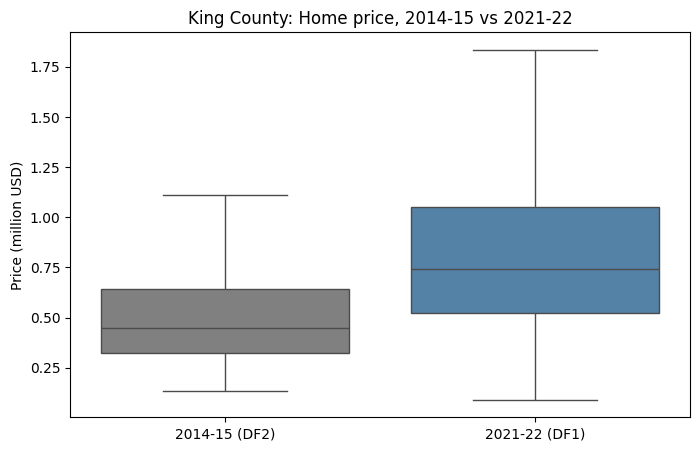

period
2014-15 (DF2)   450,000.00
2021-22 (DF1)   739,950.00
Name: price, dtype: float64
ราคามัธยฐานต่อหลังเพิ่มขึ้น 64 %


In [ ]:
plt.figure(figsize=(8, 5)) #ขนาดกราฟ

#สร้าง boxplot ราคาบ้าน (หน่วยล้านดอลลาร์) เทียบสองช่วงเวลา
#กล่อง = ช่วงราคาของบ้านครึ่งกลาง (25%-75%) เส้นในกล่อง = ราคามัธยฐาน ไม่แสดงจุด outlier
sns.boxplot(
    x='period',
    y='price_million',
    data=kc_all,
    showfliers=False,
    hue='period',
    palette=['gray', 'steelblue'],
    legend=False
)
#กำหนดชื่อกราฟ ชื่อแกน
plt.title('King County: Home price, 2014-15 vs 2021-22')
plt.xlabel('')
plt.ylabel('Price (million USD)')
plt.show()

#ราคามัธยฐานของแต่ละช่วง และเพิ่มขึ้นกี่ %
median_price = kc_all.groupby('period')['price'].median()
print(median_price)
print('ราคามัธยฐานต่อหลังเพิ่มขึ้น', round((median_price.iloc[1] / median_price.iloc[0] - 1) * 100), '%')

**สิ่งที่พบ (Q1):** ราคามัธยฐานของบ้านทั้งหมดขึ้นจากราว 450,000 ดอลลาร์ เป็นราว 740,000 ดอลลาร์ หรือแพงขึ้นราว 64% และกล่องของปี 2021-22 สูงกว่าทั้งกล่อง แปลว่าบ้านแพงขึ้นเกือบทุกระดับราคา

### 2) Insight ด้านราคาต่อตารางฟุต (Q1)

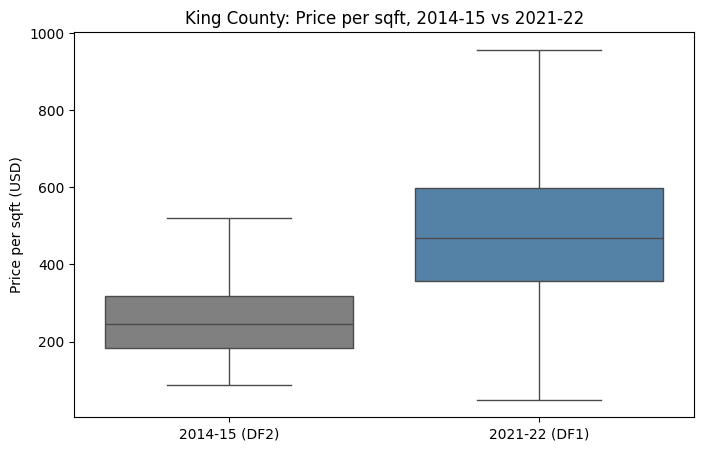

period
2014-15 (DF2)   244.61
2021-22 (DF1)   468.75
Name: price_per_sqft, dtype: float64
ราคาต่อตารางฟุตเพิ่มขึ้น 92 %


In [ ]:
plt.figure(figsize=(8, 5)) #ขนาดกราฟ

#สร้าง boxplot ราคาต่อตารางฟุต เทียบสองช่วงเวลา
sns.boxplot(
    x='period',
    y='price_per_sqft',
    data=kc_all,
    showfliers=False,
    hue='period',
    palette=['gray', 'steelblue'],
    legend=False
)
#กำหนดชื่อกราฟ ชื่อแกน
plt.title('King County: Price per sqft, 2014-15 vs 2021-22')
plt.xlabel('')
plt.ylabel('Price per sqft (USD)')
plt.show()

#ราคาต่อตารางฟุตมัธยฐานของแต่ละช่วง และเพิ่มขึ้นกี่ %
median_ppsf = kc_all.groupby('period')['price_per_sqft'].median()
print(median_ppsf)
print('ราคาต่อตารางฟุตเพิ่มขึ้น', round((median_ppsf.iloc[1] / median_ppsf.iloc[0] - 1) * 100), '%')

**สิ่งที่พบ (Q1):** ราคาต่อตารางฟุตขึ้นจากราว 245 เป็นราว 469 ดอลลาร์ หรือแพงขึ้นราว 92% ซึ่งไม่เท่ากับราคาต่อหลัง (64%) ทั้งสองตัวเลขนี้ไม่เท่ากันเพราะปี 2021-22 มีคอนโดเล็กปนอยู่ ราคาต่อหลังจึงถูกดึงลง และราคาต่อตารางฟุตถูกดันขึ้น ตัวเลขที่เชื่อถือได้กว่าอยู่ในข้อ 3.2 (เทียบบ้านจำนวนห้องนอนเดียวกัน)

## 3.2 Insight จากการเทียบบ้านที่ขาย (DF1 vs DF2)

### 1) Insight ด้านขนาดบ้าน (Q2)

**สิ่งที่พบ (Q2):** บ้านที่ขายในปี 2021-22 มีขนาดมัธยฐานราว 1,680 ตร.ฟุต เล็กกว่าปี 2014-15 (จาก 1,910 ตร.ฟุต) และกล่องของปี 2021-22 ยืดลงไปถึงบ้านที่เล็กกว่ามาก

### 2) Insight ด้านจำนวนห้องนอน (Q2)

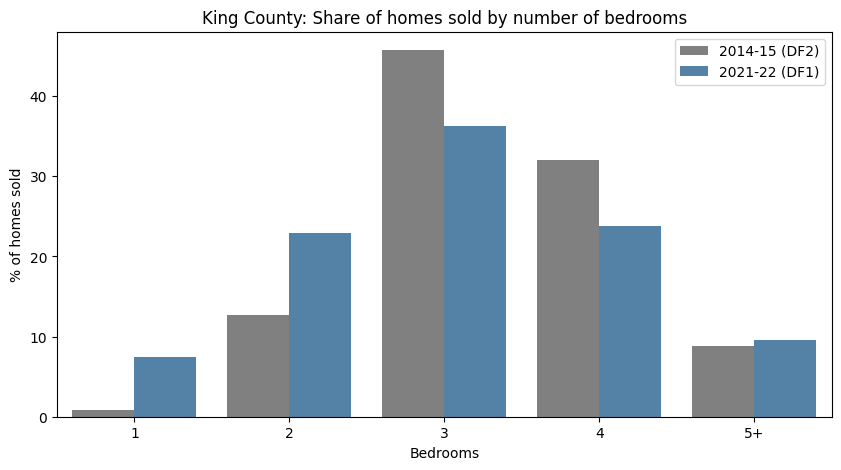

,period,bed_group,n_homes,total,percent
0,2014-15 (DF2),1,182,21380,0.85
1,2014-15 (DF2),2,2700,21380,12.63
2,2014-15 (DF2),3,9779,21380,45.74
3,2014-15 (DF2),4,6836,21380,31.97
4,2014-15 (DF2),5,1883,21380,8.81
5,2021-22 (DF1),1,708,9487,7.46
6,2021-22 (DF1),2,2177,9487,22.95
7,2021-22 (DF1),3,3442,9487,36.28
8,2021-22 (DF1),4,2255,9487,23.77
9,2021-22 (DF1),5,905,9487,9.54


In [ ]:
#ใช้เฉพาะบ้านที่มีข้อมูลห้องนอน และรวมบ้าน 5 ห้องนอนขึ้นไปเป็นกลุ่มเดียว
kc_bed = kc_all.dropna(subset=['bedrooms']).copy()
kc_bed['bed_group'] = kc_bed['bedrooms'].astype(int)
kc_bed.loc[kc_bed['bed_group'] >= 5, 'bed_group'] = 5

#นับจำนวนบ้านแต่ละกลุ่มห้องนอน แล้วคิดเป็น % ของแต่ละช่วงเวลา (สองชุดมีจำนวนบ้านต่างกัน จึงต้องเทียบเป็น %)
bed_count = kc_bed.groupby(['period', 'bed_group'])['price'].count().reset_index(name='n_homes')
period_total = kc_bed.groupby('period')['price'].count().reset_index(name='total')
bed_share = pd.merge(bed_count, period_total, on='period')
bed_share['percent'] = bed_share['n_homes'] / bed_share['total'] * 100

plt.figure(figsize=(10, 5)) #ขนาดกราฟ

#สร้างกราฟแท่งคู่ สัดส่วนบ้านแต่ละจำนวนห้องนอน เทียบสองช่วงเวลา
sns.barplot(
    x='bed_group',
    y='percent',
    hue='period',
    data=bed_share,
    palette=['grey', 'steelblue']
)
#กำหนดชื่อกราฟ ชื่อแกน
plt.xticks([0, 1, 2, 3, 4], ['1', '2', '3', '4', '5+'])
plt.title('King County: Share of homes sold by number of bedrooms')
plt.xlabel('Bedrooms')
plt.ylabel('% of homes sold')
plt.legend(title='')
plt.show()

bed_share

**สิ่งที่พบ (Q2):** บ้าน 1-2 ห้องนอนมีสัดส่วนเพิ่มจากราว 13% เป็นราว 30% ของบ้านที่ขาย สัดส่วนที่เพิ่มขึ้นนี้น่าจะมาจากการที่ DF1 รวมคอนโด แต่ DF2 แทบไม่มี จึงยังสรุปไม่ได้ว่าคนซื้อบ้านเล็กลง

### 3) Insight ด้านราคาบ้านประเภทเดียวกัน (Q1, Q2)
บ้าน 3-4 ห้องนอนส่วนใหญ่เป็นบ้านเดี่ยวทั้งสองชุดข้อมูล จึงใช้กลุ่มนี้เทียบราคาแบบบ้านกับบ้าน

,bed_group,period,sqft,price,price_per_sqft,n_homes
0,3,2014-15 (DF2),"1,680.00","414,500.00",244.06,9779
1,3,2021-22 (DF1),"1,640.00","749,950.00",453.06,3442
2,4,2014-15 (DF2),"2,400.00","546,800.00",228.21,6836
3,4,2021-22 (DF1),"2,410.00","950,000.00",427.31,2255


,price_2014,price_2022,growth_%
bed_group,,,
3,"414,500.00","749,950.00",80.93
4,"546,800.00","950,000.00",73.74


บ้าน 3-4 ห้องนอน ขนาดมัธยฐาน: [1960.0, 1920.0] ตร.ฟุต
บ้าน 3-4 ห้องนอน ราคามัธยฐานขึ้น 76 %
บ้าน 3-4 ห้องนอน ราคาต่อตารางฟุตขึ้น 88 %


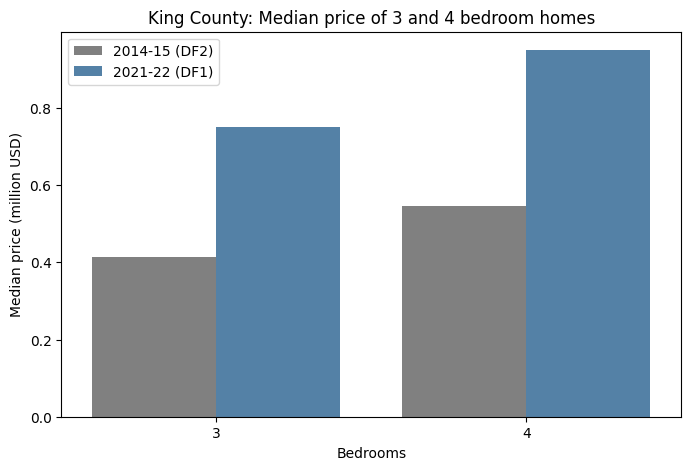

In [ ]:
#เลือกเฉพาะบ้าน 3-4 ห้องนอน (ใช้ kc_bed จาก cell ก่อนหน้า)
kc_34 = kc_bed[(kc_bed['bed_group'] == 3) | (kc_bed['bed_group'] == 4)]

#ค่ามัธยฐานของขนาด ราคา และราคาต่อตารางฟุต แยกตามจำนวนห้องนอนและช่วงเวลา
bed_compare = kc_34.groupby(['bed_group', 'period'])[['sqft', 'price', 'price_per_sqft']].median().reset_index()
bed_compare['n_homes'] = kc_34.groupby(['bed_group', 'period'])['price'].count().values
display(bed_compare)

#ราคาขึ้นกี่ % ในแต่ละกลุ่ม (เทียบบ้านจำนวนห้องนอนเดียวกัน)
growth_by_bed = bed_compare.pivot_table(values='price', index='bed_group', columns='period')
growth_by_bed.columns = ['price_2014', 'price_2022']
growth_by_bed['growth_%'] = (growth_by_bed['price_2022'] / growth_by_bed['price_2014'] - 1) * 100
display(growth_by_bed)

#รวมบ้าน 3-4 ห้องนอนเป็นกลุ่มเดียว
median_34 = kc_34.groupby('period')[['sqft', 'price', 'price_per_sqft']].median()
print('บ้าน 3-4 ห้องนอน ขนาดมัธยฐาน:', median_34['sqft'].tolist(), 'ตร.ฟุต')
print('บ้าน 3-4 ห้องนอน ราคามัธยฐานขึ้น', round((median_34['price'].iloc[1] / median_34['price'].iloc[0] - 1) * 100), '%')
print('บ้าน 3-4 ห้องนอน ราคาต่อตารางฟุตขึ้น', round((median_34['price_per_sqft'].iloc[1] / median_34['price_per_sqft'].iloc[0] - 1) * 100), '%')

#แปลงราคาเป็นหน่วยล้านดอลลาร์ เพื่อให้แกนอ่านง่าย
bed_compare['price_million'] = bed_compare['price'] / 1000000

plt.figure(figsize=(8, 5)) #ขนาดกราฟ

#สร้างกราฟแท่งคู่ ราคามัธยฐานของบ้าน 3 และ 4 ห้องนอน เทียบสองช่วงเวลา
sns.barplot(
    x='bed_group',
    y='price_million',
    hue='period',
    data=bed_compare,
    palette=['grey', 'steelblue']
)
#กำหนดชื่อกราฟ ชื่อแกน
plt.title('King County: Median price of 3 and 4 bedroom homes')
plt.xlabel('Bedrooms')
plt.ylabel('Median price (million USD)')
plt.legend(title='')
plt.show()

**สิ่งที่พบ (Q1, Q2):** บ้าน 3-4 ห้องนอนซึ่งเป็นบ้านเดี่ยวในทั้งสองชุดข้อมูล มีขนาดใกล้เคียงกัน (มัธยฐานราว 1,960 กับ 1,920 ตร.ฟุต) พอเทียบแบบบ้านกับบ้าน ราคามัธยฐานขึ้นราว 76% และราคาต่อตารางฟุตขึ้นราว 88% แยกดูบ้าน 3 ห้องนอนขึ้นราว 81% บ้าน 4 ห้องนอนขึ้นราว 74% ตัวเลขชุดนี้คือคำตอบ Q1 ที่เราเชื่อถือได้ที่สุด

## 3.3 Insight จากการเทียบปัจจัยที่สัมพันธ์กับราคา (DF1 vs DF2)

### 1) Insight ด้านขนาดบ้านและจำนวนห้อง (Q3)

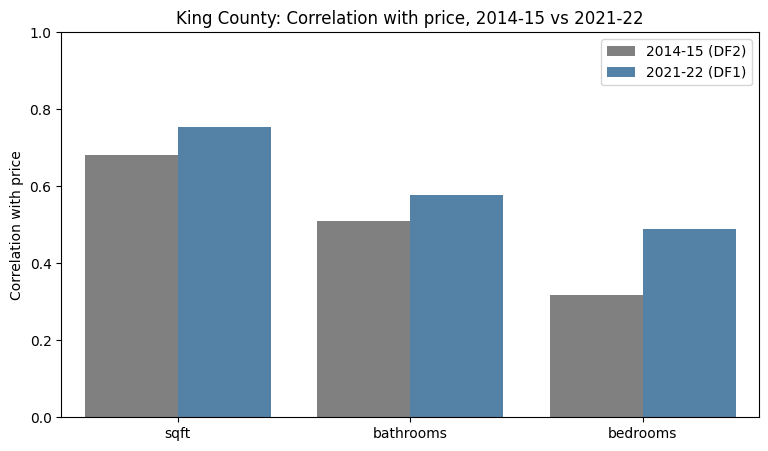

,feature,correlation,period
0,sqft,0.68,2014-15 (DF2)
1,bathrooms,0.51,2014-15 (DF2)
2,bedrooms,0.32,2014-15 (DF2)
0,sqft,0.75,2021-22 (DF1)
1,bathrooms,0.58,2021-22 (DF1)
2,bedrooms,0.49,2021-22 (DF1)


In [ ]:
#ค่า correlation ของขนาดบ้าน ห้องน้ำ และห้องนอน กับราคา แยกแต่ละช่วงเวลา (ค่าใกล้ 1 = ยิ่งมากยิ่งแพง)
corr_2014 = kc_2014[['price', 'sqft', 'bathrooms', 'bedrooms']].corr()['price'].drop('price').reset_index()
corr_2014.columns = ['feature', 'correlation']
corr_2014['period'] = '2014-15 (DF2)'

corr_2022 = kc_2022[['price', 'sqft', 'bathrooms', 'bedrooms']].corr()['price'].drop('price').reset_index()
corr_2022.columns = ['feature', 'correlation']
corr_2022['period'] = '2021-22 (DF1)'

#ต่อสองตารางกันไว้ทำกราฟเทียบ
corr_compare = pd.concat([corr_2014, corr_2022])

plt.figure(figsize=(9, 5)) #ขนาดกราฟ

#สร้างกราฟแท่งคู่ ค่า correlation กับราคา เทียบสองช่วงเวลา
sns.barplot(
    x='feature',
    y='correlation',
    hue='period',
    data=corr_compare,
    palette=['grey', 'steelblue']
)
#กำหนดชื่อกราฟ ชื่อแกน
plt.title('King County: Correlation with price, 2014-15 vs 2021-22')
plt.xlabel('')
plt.ylabel('Correlation with price')
plt.ylim(0, 1)
plt.legend(title='')
plt.show()

corr_compare

**สิ่งที่พบ (Q3):**  ปัจจัยที่สัมพันธ์กับราคา ทั้งสองช่วง ขนาดบ้านสัมพันธ์กับราคามากที่สุด รองลงมาคือห้องน้ำ แล้วค่อยเป็นห้องนอน ค่า correlation ปี 2021-22 สูงกว่าทุกตัว เช่น ขนาดบ้านจาก 0.68 เป็น 0.75 แต่ส่วนใหญ่น่าจะเป็นเพราะข้อมูลมีทั้งคอนโดเล็กและบ้านใหญ่ปนกัน ราคาเลยกระจายกว้างขึ้น สิ่งที่สรุปได้คือลำดับความสำคัญยังเหมือนเดิม

## 3.4 Insight จากการเทียบรายย่าน (DF1 + DF2)

### 1) Insight ด้านย่านที่ราคาโตเร็วที่สุด (Q4)

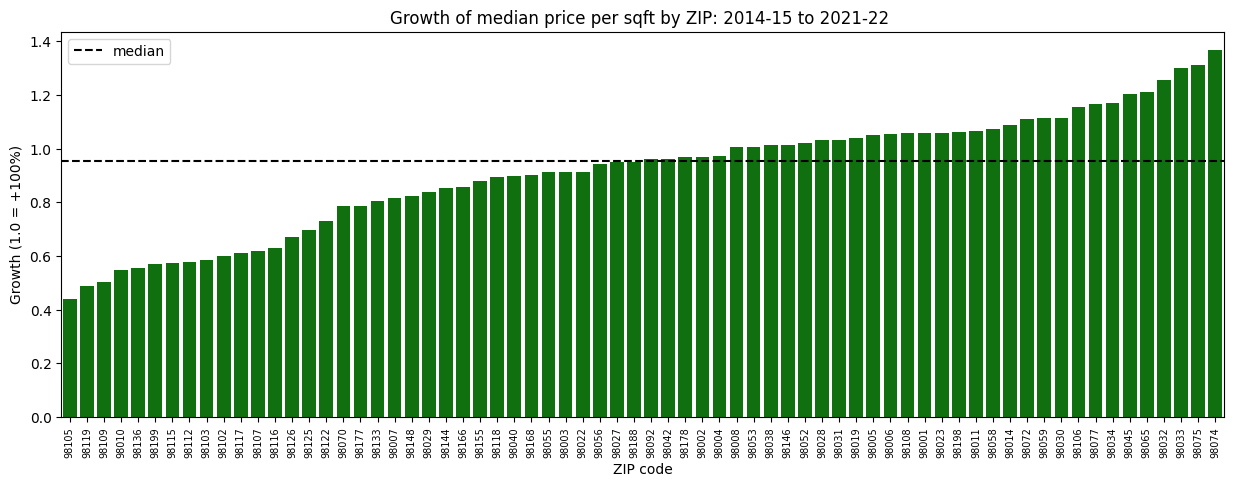

,zipcode,ppsf_2014,ppsf_2022,growth_ppsf,growth_per_year,dist_km,size_change_%
37,98074,255.34,604.40,1.37,0.13,21.57,-3.38
38,98075,250.52,578.87,1.31,0.12,23.40,3.79
21,98033,322.83,742.21,1.30,0.12,13.69,-1.84
20,98032,146.23,330.05,1.26,0.12,26.26,-15.35
34,98065,206.38,456.02,1.21,0.12,35.67,-15.43


,zipcode,ppsf_2014,ppsf_2022,growth_ppsf,growth_per_year,dist_km,size_change_%
43,98105,387.76,558.52,0.44,0.05,7.18,-5.53
53,98119,416.35,618.81,0.49,0.06,4.56,-32.61
47,98109,425.27,638.46,0.50,0.06,3.77,-50.82
8,98010,194.21,300.83,0.55,0.06,39.40,35.54
58,98136,319.44,496.47,0.55,0.06,8.40,23.27


In [ ]:
#เรียง ZIP จากโตน้อยไปโตมาก
zip_sorted = zip_df.sort_values('growth_ppsf')

plt.figure(figsize=(15, 5)) #ขนาดกราฟ

#สร้างกราฟแท่ง การเติบโตของราคาต่อตารางฟุตแต่ละ ZIP (1 แท่ง = 1 ย่าน)
sns.barplot(
    x='zipcode',
    y='growth_ppsf',
    data=zip_sorted,
    order=zip_sorted['zipcode'],
    color='green'
)
#เส้นประ = ค่ามัธยฐานของทุก ZIP
plt.axhline(zip_df['growth_ppsf'].median(), color='black', linestyle='--', label='median')
plt.legend()
#กำหนดชื่อกราฟ ชื่อแกน
plt.title('Growth of median price per sqft by ZIP: 2014-15 to 2021-22 ')
plt.xlabel('ZIP code')
plt.ylabel('Growth (1.0 = +100%)')
plt.xticks(rotation=90, fontsize=7)
plt.show()

#ZIP ที่ราคาโตเร็วที่สุด และช้าที่สุด 5 อันดับ (size_change_% ติดลบมาก = ปี 2022 ขายบ้านหลังเล็กกว่าเดิมมาก)
show_cols = ['zipcode', 'ppsf_2014', 'ppsf_2022', 'growth_ppsf', 'growth_per_year', 'dist_km', 'size_change_%']
display(zip_df.sort_values('growth_ppsf', ascending=False)[show_cols].head())
display(zip_df.sort_values('growth_ppsf')[show_cols].head())

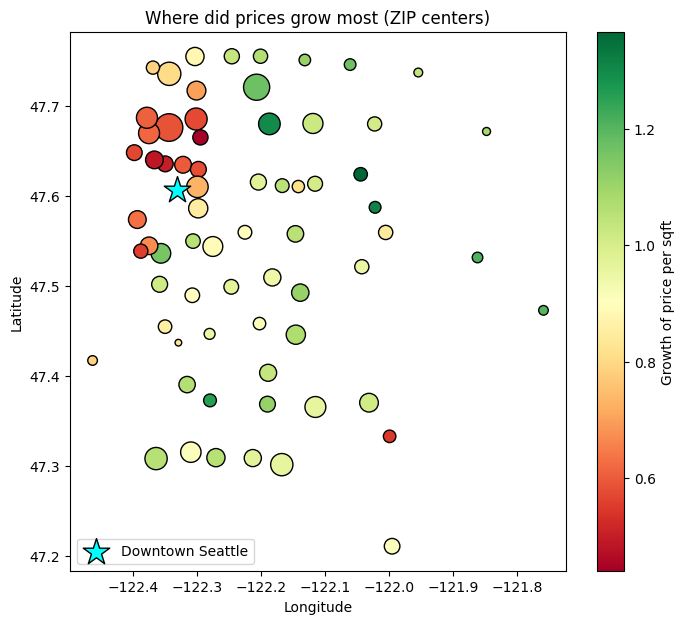

In [ ]:
plt.figure(figsize=(8, 7)) #ขนาดกราฟ

#แผนที่ ZIP: สีเขียว = โตมาก, สีแดง = โตน้อย, ขนาดจุด = จำนวนบ้านที่ขายปี 2021-22
plt.scatter(zip_df['long'], zip_df['lat'], c=zip_df['growth_ppsf'], s=zip_df['n_2022'], cmap='RdYlGn', edgecolor='black')
plt.colorbar(label='Growth of price per sqft')

#ดาวสีฟ้า = ใจกลางเมือง Seattle
plt.scatter(-122.3321, 47.6062, marker='*', s=400, color='cyan', edgecolor='black', label='Downtown Seattle')
plt.legend(loc='lower left')

#กำหนดชื่อกราฟ ชื่อแกน
plt.title('Where did prices grow most (ZIP centers)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

**สิ่งที่พบ (Q4):** ราคาต่อตารางฟุตแต่ละย่านโตเฉลี่ยราว 91% แต่ต่างกันมาก ตั้งแต่ราว +44% ถึง +137% ย่านที่โตเร็วส่วนใหญ่เป็นชานเมืองฝั่งตะวันออก ส่วนย่านที่โตช้าส่วนใหญ่อยู่ใกล้ใจกลาง Seattle (จุดสีแดงที่อยู่ใกล้ดาว) ย่านใกล้เมืองเหล่านี้มีคอนโดเยอะ ในตารางย่านที่โตช้า 98109 (South Lake Union) กับ 98119 (Queen Anne) มี `size_change_%` ติดลบถึงราว -51% และ -33% แปลว่าปี 2022 ขายบ้าน/คอนโดหลังเล็กกว่าเดิมมาก การโตที่ต่ำส่วนหนึ่งจึงมาจากการเทียบบ้านต่างประเภท ไม่ใช่ราคาขึ้นช้าอย่างเดียว

### 2) Insight ด้านลักษณะของย่านที่โตเร็ว (Q4)

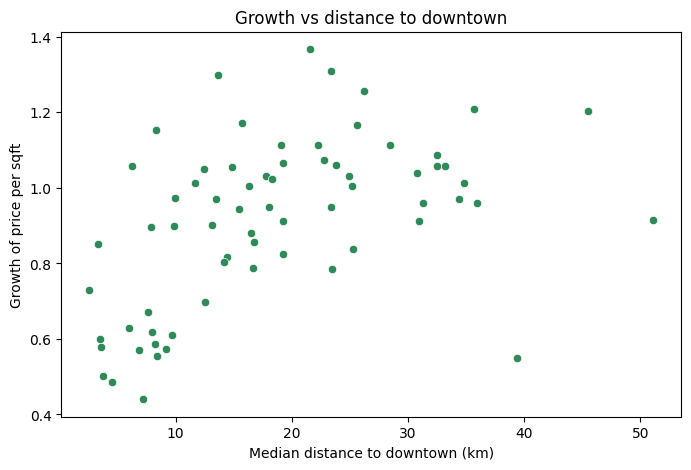

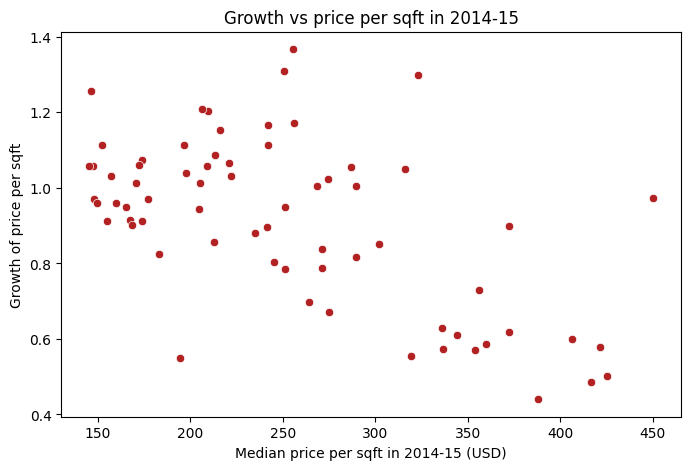

,growth_ppsf,dist_km,ppsf_2014,grade
growth_ppsf,1.00,0.49,-0.58,0.15
dist_km,0.49,1.00,-0.71,-0.05
ppsf_2014,-0.58,-0.71,1.00,0.48
grade,0.15,-0.05,0.48,1.00


In [ ]:
plt.figure(figsize=(8, 5)) #ขนาดกราฟ

#สร้างแผนภาพจุด แกน x เป็นระยะทางจาก downtown แกน y เป็นการเติบโตของราคา (1 จุด = 1 ZIP)
sns.scatterplot(
    x='dist_km',
    y='growth_ppsf',
    data=zip_df,
    color='seagreen'
)
#กำหนดชื่อกราฟ ชื่อแกน
plt.title('Growth vs distance to downtown')
plt.xlabel('Median distance to downtown (km)')
plt.ylabel('Growth of price per sqft')
plt.show()

plt.figure(figsize=(8, 5)) #ขนาดกราฟ

#สร้างแผนภาพจุด แกน x เป็นราคาต่อตารางฟุตปี 2014-15 แกน y เป็นการเติบโตของราคา
sns.scatterplot(
    x='ppsf_2014',
    y='growth_ppsf',
    data=zip_df,
    color='firebrick'
)
#กำหนดชื่อกราฟ ชื่อแกน
plt.title('Growth vs price per sqft in 2014-15')
plt.xlabel('Median price per sqft in 2014-15 (USD)')
plt.ylabel('Growth of price per sqft')
plt.show()

#ค่า correlation ระหว่างการเติบโต ระยะทาง และราคาเดิม (ดูด้วยว่าระยะทางกับราคาเดิมสัมพันธ์กันเองแค่ไหน)
zip_df[['growth_ppsf', 'dist_km', 'ppsf_2014', 'grade']].corr()

In [ ]:
#Data Profiling: ZIP ที่โตมากกว่าค่ามัธยฐาน = 'fast growth' ที่เหลือ = 'slow growth'
growth_median = zip_df['growth_ppsf'].median()
zip_df['growth_group'] = 'slow growth'
zip_df.loc[zip_df['growth_ppsf'] > growth_median, 'growth_group'] = 'fast growth'

#ค่าเฉลี่ยของลักษณะย่านในแต่ละกลุ่ม
zip_df.groupby('growth_group')[['growth_ppsf', 'ppsf_2014', 'price_2014', 'dist_km', 'size_2014', 'size_change_%', 'grade']].mean()

,growth_ppsf,ppsf_2014,price_2014,dist_km,size_2014,size_change_%,grade
growth_group,,,,,,,
fast growth,1.09,219.15,"457,261.76",23.18,"2,082.00",-6.02,7.72
slow growth,0.74,286.19,"502,559.57",14.12,"1,803.65",-8.63,7.55


**สิ่งที่พบ (Q4):** ย่านที่อยู่ไกลกว่า (r = +0.49) และย่านที่เคยถูกกว่า (r = -0.58) ราคาโตเร็วกว่า แต่ระยะทางกับราคาเดิมสัมพันธ์กันเอง (r = -0.71 คือย่านไกลเมืองมักถูกกว่า) จึงแยกไม่ได้ว่าตัวไหนเป็นสาเหตุ และมีข้อยกเว้น เช่น Kirkland (98033) อยู่ใกล้เมืองและเคยแพง แต่โตเร็วติดอันดับต้น ๆ ส่วน Black Diamond (98010) อยู่ไกลและเคยถูก แต่โตช้า เมื่อแบ่ง ZIP เป็น 2 กลุ่ม ย่านที่โตเร็วมีราคาเดิมต่ำกว่า อยู่ไกลเมืองกว่า และขนาดบ้านที่ขายลดลงน้อยกว่าเล็กน้อย (ราว -6% เทียบกับ -9%) (ดูตารางด้านบน)

## 3.5 การตั้งสมมติฐานและทดสอบ (Hypothesis Testing)

ทดสอบเพื่อยืนยันคำตอบ Q1-Q4 ทุกข้อตั้ง H0 = ไม่มีความแตกต่าง / ไม่มีความสัมพันธ์ และ H1 = มีความแตกต่าง / มีความสัมพันธ์ ถ้า p-value < 0.05 จะปฏิเสธ H0 (สรุปว่ามีนัยสำคัญทางสถิติ)

ราคาบ้านเบ้ขวา ไม่ได้กระจายแบบระฆังคว่ำ จึงใช้วิธีที่เทียบด้วยลำดับ (rank) แทนค่าจริง คือ Mann-Whitney U (เทียบ 2 กลุ่ม) และ Spearman (หาความสัมพันธ์) และดู effect size ด้วย เพราะข้อมูลเยอะมาก p-value จะต่ำเกือบทุกครั้ง effect size บอกว่าต่างกัน "มากแค่ไหน"
- Mann-Whitney ใช้ rank-biserial เป็น effect size มีค่า -1 ถึง 1 (0 = ไม่ต่างกัน, ใกล้ 1 = กลุ่มปี 2021-22 สูงกว่าเกือบทุกคู่)
- Spearman ใช้ค่า rho เป็น effect size เลย (ใกล้ 0 = ไม่สัมพันธ์, ใกล้ 1 หรือ -1 = สัมพันธ์มาก)

| ข้อ | สมมติฐาน (H1) | คำถาม | วิธีทดสอบ |
|---|---|---|---|
| 1 | บ้าน 3-4 ห้องนอน ราคาต่อตารางฟุตปี 2021-22 ต่างจากปี 2014-15 | Q1 | Mann-Whitney U (`stats.mannwhitneyu`) |
| 2 | บ้าน 3-4 ห้องนอน ขนาดบ้านสองช่วงต่างกัน | Q2 | Mann-Whitney U (`stats.mannwhitneyu`) |
| 3 | ปี 2021-22 บ้านที่ใหญ่กว่ามีราคาสูงกว่า | Q3 | Spearman (`stats.spearmanr`) |
| 4 | ย่านที่อยู่ไกล downtown มีราคาโตเร็วกว่า | Q4 | Spearman (`stats.spearmanr`) |
| 5 | ย่านที่ราคาเดิมต่ำ มีราคาโตเร็วกว่า | Q4 | Spearman (`stats.spearmanr`) |

In [ ]:
#effect size ของ Mann-Whitney (rank-biserial): บอกว่าสองกลุ่มต่างกันมากแค่ไหน มีค่า -1 ถึง 1
def rank_biserial(u, n1, n2):
    return 2 * u / (n1 * n2) - 1

#ใช้เฉพาะบ้าน 3-4 ห้องนอน เพื่อเทียบบ้านประเภทเดียวกัน
kc_2014_34 = kc_2014[kc_2014['bedrooms'].between(3, 4)]
kc_2022_34 = kc_2022[kc_2022['bedrooms'].between(3, 4)]

#สมมติฐานข้อ 1: ราคาต่อตารางฟุต บ้าน 3-4 ห้องนอน ปี 2021-22 vs ปี 2014-15
ppsf_22 = kc_2022_34['price_per_sqft'].dropna()
ppsf_14 = kc_2014_34['price_per_sqft'].dropna()
u1, p1 = stats.mannwhitneyu(ppsf_22, ppsf_14)
e1 = rank_biserial(u1, len(ppsf_22), len(ppsf_14))

#สมมติฐานข้อ 2: ขนาดบ้าน 3-4 ห้องนอน ปี 2021-22 vs ปี 2014-15
size_22 = kc_2022_34['sqft'].dropna()
size_14 = kc_2014_34['sqft'].dropna()
u2, p2 = stats.mannwhitneyu(size_22, size_14)
e2 = rank_biserial(u2, len(size_22), len(size_14))

#สมมติฐานข้อ 3: ขนาดบ้าน vs ราคา ปี 2021-22
kc_2022_with_size = kc_2022.dropna(subset=['sqft'])
r3, p3 = stats.spearmanr(kc_2022_with_size['sqft'], kc_2022_with_size['price'])

#สมมติฐานข้อ 4: ระยะทางจาก downtown vs การเติบโตของราคาจากปี 2014-15 ถึง 2021-22
r4, p4 = stats.spearmanr(zip_df['dist_km'], zip_df['growth_ppsf'])

#สมมติฐานข้อ 5: ราคาตั้งต้น (ราคาต่อตารางฟุตปี 2014-15) vs การเติบโตของราคาจนถึงปี 2021-22
r5, p5 = stats.spearmanr(zip_df['ppsf_2014'], zip_df['growth_ppsf'])

#สรุปผลการทดสอบทั้ง 5 ข้อเป็นตาราง
test_results = pd.DataFrame({
    'hypothesis': ['1. ราคาต่อตารางฟุตเปลี่ยน (3-4 ห้องนอน)', '2. ขนาดบ้านเปลี่ยน (3-4 ห้องนอน)', '3. บ้านใหญ่แพงกว่า',
                   '4. ไกลเมืองโตเร็วกว่า', '5. ราคาเดิมต่ำโตเร็วกว่า'],
    'question': ['Q1', 'Q2', 'Q3', 'Q4', 'Q4'],
    'test': ['Mann-Whitney U', 'Mann-Whitney U', 'Spearman', 'Spearman', 'Spearman'],
    'effect_size': [e1, e2, r3, r4, r5],
    'p_value': [p1, p2, p3, p4, p5]
})
test_results['result'] = 'ไม่ปฏิเสธ H0'
test_results.loc[test_results['p_value'] < 0.05, 'result'] = 'ปฏิเสธ H0 (มีนัยสำคัญ)'

#แสดง p-value แบบวิทยาศาสตร์ เช่น 1.23e-05 (ถ้าแสดงทศนิยม 2 ตำแหน่ง จะเห็นเป็น 0.00 หมด)
test_results['p_value'] = test_results['p_value'].map('{:.2e}'.format)
test_results

,hypothesis,question,test,effect_size,p_value,result
0,1. ราคาต่อตารางฟุตเปลี่ยน (3-4 ห้องนอน),Q1,Mann-Whitney U,0.78,0.00e+00,ปฏิเสธ H0 (มีนัยสำคัญ)
1,2. ขนาดบ้านเปลี่ยน (3-4 ห้องนอน),Q2,Mann-Whitney U,-0.03,1.60e-04,ปฏิเสธ H0 (มีนัยสำคัญ)
2,3. บ้านใหญ่แพงกว่า,Q3,Spearman,0.76,0.00e+00,ปฏิเสธ H0 (มีนัยสำคัญ)
3,4. ไกลเมืองโตเร็วกว่า,Q4,Spearman,0.54,2.04e-06,ปฏิเสธ H0 (มีนัยสำคัญ)
4,5. ราคาเดิมต่ำโตเร็วกว่า,Q4,Spearman,-0.50,1.18e-05,ปฏิเสธ H0 (มีนัยสำคัญ)



**สรุป:** ทุกข้อมี p-value < 0.05 แต่ effect size บอกว่าต่างกันมากน้อยไม่เท่ากัน ข้อ 1 ราคาต่อตารางฟุตของบ้าน 3-4 ห้องนอนต่างกันมาก (0.78 แปลว่าบ้านปี 2021-22 แพงกว่าเกือบทุกคู่) ข้อ 2 ขนาดบ้านต่างกันอย่างมีนัยสำคัญ แต่ effect size แค่ -0.03 คือแทบไม่ต่างกันเลย ที่ได้ p-value ต่ำเพราะข้อมูลมีหลายหมื่นหลัง ข้อนี้จึงยืนยันว่าบ้าน 3-4 ห้องนอนของสองช่วงขนาดเท่ากันในทางปฏิบัติ เทียบราคากันได้ ข้อ 3 ขนาดบ้านสัมพันธ์กับราคาสูง (0.76) ข้อ 4-5 สัมพันธ์ระดับปานกลาง (0.54 และ -0.50) แต่ทั้งสองข้ออาจเป็นปรากฏการณ์เดียวกัน เพราะย่านไกลเมืองมักเป็นย่านที่ราคาเดิมถูก

# Part 4: การสรุปผล และไอเดียต่อยอด

## 1) สรุปผลการวิเคราะห์

1. ราคาบ้านใน King County แพงขึ้นมาก (Q1): เมื่อเทียบบ้านประเภทเดียวกัน  ราคามัธยฐานขึ้นราว 76% และราคาต่อตารางฟุตขึ้นราว 88% ในเวลาประมาณ 7 ปี
2. ข้อมูลสองชุดเก็บบ้านต่างประเภท ต้องเทียบบ้านแบบเดียวกัน (Q2): DF2 เกือบทั้งหมดเป็นบ้านเดี่ยว ส่วน DF1 มีคอนโดปน บ้าน 1-2 ห้องนอนใน DF1 จึงมีสัดส่วนสูงกว่ามาก (ราว 30% เทียบกับ 13%) ถ้าเทียบบ้านทั้งหมดรวมกัน ราคาต่อหลังจะดูขึ้นน้อยไป และราคาต่อตารางฟุตจะดูขึ้นมากไป
3. ขนาดบ้านยังสำคัญที่สุด (Q3): ทั้งสองช่วงเวลา ลำดับความสำคัญเหมือนเดิม คือขนาดบ้าน > ห้องน้ำ > ห้องนอน ค่า correlation ที่สูงขึ้นในปี 2021-22 ส่วนใหญ่มาจากข้อมูลที่มีบ้านหลายประเภทปนกัน
4. ย่านไกลเมืองและเคยถูกโตเร็วกว่า (Q4): ราคาต่อตารางฟุตแต่ละย่านโตเฉลี่ยราว 91% ย่านไกลเมืองและเคยถูกโตเร็วกว่า แต่สองปัจจัยนี้ไปด้วยกัน จึงยังแยกไม่ได้ว่าอะไรเป็นสาเหตุ และย่านใกล้เมืองที่ดูโตช้าส่วนหนึ่งเป็นเพราะปี 2022 มีคอนโดปน

## 2) ข้อเสนอแนะเชิงกลยุทธ์

1. ผู้ซื้อและนักลงทุน: เวลาเทียบราคาบ้านต่างช่วงเวลาหรือต่างย่าน ควรเทียบบ้านประเภทและขนาดเดียวกัน เพราะการเทียบราคาต่อหลังหรือราคาต่อตารางฟุตของบ้านทุกแบบรวมกัน อาจทำให้ตัดสินใจผิด

## 3) ไอเดียต่อยอด

1. โมเดลประเมินราคาบ้าน King County: ใช้ขนาดบ้าน ห้อง และ ZIP ทำนายราคา แยกบ้านเดี่ยวกับคอนโด แล้วเทียบว่าโมเดลจากปี 2014 กับปี 2022 ให้น้ำหนักแต่ละปัจจัยต่างกันแค่ไหน
2. ติดตามราคารายย่าน: ถ้ามีข้อมูลปีอื่นเพิ่ม จะดูได้ว่าย่านที่โตเร็วยังโตต่อหรือเริ่มชะลอ และแยกได้ว่าระยะทางกับราคาเดิม ตัวไหนมีผลจริง